In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

%matplotlib inline


In [30]:
df = pd.read_csv("sales_data_sample - sales_data_sample.csv", encoding="Latin-1")
df.head()


,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,STATUS,QTR_ID,MONTH_ID,YEAR_ID,...,ADDRESSLINE1,ADDRESSLINE2,CITY,STATE,POSTALCODE,COUNTRY,TERRITORY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
0,10107,30,95.70,2,2871.00,2/24/2003 0:00,Shipped,1,2,2003,...,897 Long Airport Avenue,NaN,NYC,NY,10022,USA,NaN,Yu,Kwai,Small
1,10121,34,81.35,5,2765.90,5/7/2003 0:00,Shipped,2,5,2003,...,59 rue de l'Abbaye,NaN,Reims,NaN,51100,France,EMEA,Henriot,Paul,Small
2,10134,41,94.74,2,3884.34,7/1/2003 0:00,Shipped,3,7,2003,...,27 rue du Colonel Pierre Avia,NaN,Paris,NaN,75508,France,EMEA,Da Cunha,Daniel,Medium
3,10145,45,83.26,6,3746.70,8/25/2003 0:00,Shipped,3,8,2003,...,78934 Hillside Dr.,NaN,Pasadena,CA,90003,USA,NaN,Young,Julie,Medium
4,10159,49,100.00,14,5205.27,10/10/2003 0:00,Shipped,4,10,2003,...,7734 Strong St.,NaN,San Francisco,CA,NaN,USA,NaN,Brown,Julie,Medium


In [31]:
print("Dataset shape:", df.shape)
display(df.head())
display(df.describe(include="all"))


Dataset shape: (2823, 25)


,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,STATUS,QTR_ID,MONTH_ID,YEAR_ID,...,ADDRESSLINE1,ADDRESSLINE2,CITY,STATE,POSTALCODE,COUNTRY,TERRITORY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
0,10107,30,95.70,2,2871.00,2/24/2003 0:00,Shipped,1,2,2003,...,897 Long Airport Avenue,NaN,NYC,NY,10022,USA,NaN,Yu,Kwai,Small
1,10121,34,81.35,5,2765.90,5/7/2003 0:00,Shipped,2,5,2003,...,59 rue de l'Abbaye,NaN,Reims,NaN,51100,France,EMEA,Henriot,Paul,Small
2,10134,41,94.74,2,3884.34,7/1/2003 0:00,Shipped,3,7,2003,...,27 rue du Colonel Pierre Avia,NaN,Paris,NaN,75508,France,EMEA,Da Cunha,Daniel,Medium
3,10145,45,83.26,6,3746.70,8/25/2003 0:00,Shipped,3,8,2003,...,78934 Hillside Dr.,NaN,Pasadena,CA,90003,USA,NaN,Young,Julie,Medium
4,10159,49,100.00,14,5205.27,10/10/2003 0:00,Shipped,4,10,2003,...,7734 Strong St.,NaN,San Francisco,CA,NaN,USA,NaN,Brown,Julie,Medium


,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,STATUS,QTR_ID,MONTH_ID,YEAR_ID,...,ADDRESSLINE1,ADDRESSLINE2,CITY,STATE,POSTALCODE,COUNTRY,TERRITORY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
count,2823.000000,2823.000000,2823.000000,2823.000000,2823.000000,2823,2823,2823.000000,2823.000000,2823.00000,...,2823,302,2823,1337,2747,2823,1749,2823,2823,2823
unique,NaN,NaN,NaN,NaN,NaN,252,6,NaN,NaN,NaN,...,92,9,73,16,73,19,3,77,72,3
top,NaN,NaN,NaN,NaN,NaN,11/14/2003 0:00,Shipped,NaN,NaN,NaN,...,"C/ Moralzarzal, 86",Level 3,Madrid,CA,28034,USA,EMEA,Freyre,Diego,Medium
freq,NaN,NaN,NaN,NaN,NaN,38,2617,NaN,NaN,NaN,...,259,55,304,416,259,1004,1407,259,259,1384
mean,10258.725115,35.092809,83.658544,6.466171,3553.889072,NaN,NaN,2.717676,7.092455,2003.81509,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,92.085478,9.741443,20.174277,4.225841,1841.865106,NaN,NaN,1.203878,3.656633,0.69967,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,10100.000000,6.000000,26.880000,1.000000,482.130000,NaN,NaN,1.000000,1.000000,2003.00000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,10180.000000,27.000000,68.860000,3.000000,2203.430000,NaN,NaN,2.000000,4.000000,2003.00000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,10262.000000,35.000000,95.700000,6.000000,3184.800000,NaN,NaN,3.000000,8.000000,2004.00000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,10333.500000,43.000000,100.000000,9.000000,4508.000000,NaN,NaN,4.000000,11.000000,2004.00000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [32]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 2823 entries, 0 to 2822
Data columns (total 25 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ORDERNUMBER       2823 non-null   int64  
 1   QUANTITYORDERED   2823 non-null   int64  
 2   PRICEEACH         2823 non-null   float64
 3   ORDERLINENUMBER   2823 non-null   int64  
 4   SALES             2823 non-null   float64
 5   ORDERDATE         2823 non-null   str    
 6   STATUS            2823 non-null   str    
 7   QTR_ID            2823 non-null   int64  
 8   MONTH_ID          2823 non-null   int64  
 9   YEAR_ID           2823 non-null   int64  
 10  PRODUCTLINE       2823 non-null   str    
 11  MSRP              2823 non-null   int64  
 12  PRODUCTCODE       2823 non-null   str    
 13  CUSTOMERNAME      2823 non-null   str    
 14  PHONE             2823 non-null   str    
 15  ADDRESSLINE1      2823 non-null   str    
 16  ADDRESSLINE2      302 non-null    str    
 17  CITY  

In [33]:
df.isnull().sum()


ORDERNUMBER            0
QUANTITYORDERED        0
PRICEEACH              0
ORDERLINENUMBER        0
SALES                  0
ORDERDATE              0
STATUS                 0
QTR_ID                 0
MONTH_ID               0
YEAR_ID                0
PRODUCTLINE            0
MSRP                   0
PRODUCTCODE            0
CUSTOMERNAME           0
PHONE                  0
ADDRESSLINE1           0
ADDRESSLINE2        2521
CITY                   0
STATE               1486
POSTALCODE            76
COUNTRY                0
TERRITORY           1074
CONTACTLASTNAME        0
CONTACTFIRSTNAME       0
DEALSIZE               0
dtype: int64

In [34]:
columns_to_drop = [
    "ADDRESSLINE1", "ADDRESSLINE2", "STATUS", "POSTALCODE", "CITY",
    "TERRITORY", "PHONE", "STATE", "CONTACTFIRSTNAME",
    "CONTACTLASTNAME", "CUSTOMERNAME", "ORDERNUMBER"
]
df = df.drop(columns=columns_to_drop, errors="ignore")

print("Missing values after dropping columns:")
display(df.isnull().sum())


Missing values after dropping columns:


QUANTITYORDERED    0
PRICEEACH          0
ORDERLINENUMBER    0
SALES              0
ORDERDATE          0
QTR_ID             0
MONTH_ID           0
YEAR_ID            0
PRODUCTLINE        0
MSRP               0
PRODUCTCODE        0
COUNTRY            0
DEALSIZE           0
dtype: int64

In [35]:
# Inspect categorical values
for col in ["COUNTRY", "PRODUCTLINE", "DEALSIZE"]:
    if col in df.columns:
        print(f"Unique values in {col}:")
        print(df[col].unique())
        print()


Unique values in COUNTRY:
<StringArray>
[        'USA',      'France',      'Norway',   'Australia',     'Finland',
     'Austria',          'UK',       'Spain',      'Sweden',   'Singapore',
      'Canada',       'Japan',       'Italy',     'Denmark',     'Belgium',
 'Philippines',     'Germany', 'Switzerland',     'Ireland']
Length: 19, dtype: str

Unique values in PRODUCTLINE:
<StringArray>
[     'Motorcycles',     'Classic Cars', 'Trucks and Buses',
     'Vintage Cars',           'Planes',            'Ships',
           'Trains']
Length: 7, dtype: str

Unique values in DEALSIZE:
<StringArray>
['Small', 'Medium', 'Large']
Length: 3, dtype: str



In [36]:
# One-hot encode PRODUCTLINE and DEALSIZE.
df = pd.get_dummies(df, columns=["PRODUCTLINE", "DEALSIZE"], dtype=int)

# Convert PRODUCTCODE from text to numeric category codes.
if "PRODUCTCODE" in df.columns:
    df["PRODUCTCODE"] = pd.Categorical(df["PRODUCTCODE"]).codes

# Remove ORDERDATE; time-related numeric columns are already present.
df = df.drop(columns=["ORDERDATE"], errors="ignore")

# Convert any remaining non-numeric columns to numeric dummy variables.
df = pd.get_dummies(df, drop_first=False, dtype=int)

# Handle missing values in numeric columns.
df = df.select_dtypes(include=[np.number]).copy()
df = df.fillna(df.median(numeric_only=True))

print("Processed data shape:", df.shape)
display(df.head())
print(df.dtypes)


Processed data shape: (2823, 38)


,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,QTR_ID,MONTH_ID,YEAR_ID,MSRP,PRODUCTCODE,PRODUCTLINE_Classic Cars,...,COUNTRY_Italy,COUNTRY_Japan,COUNTRY_Norway,COUNTRY_Philippines,COUNTRY_Singapore,COUNTRY_Spain,COUNTRY_Sweden,COUNTRY_Switzerland,COUNTRY_UK,COUNTRY_USA
0,30,95.70,2,2871.00,1,2,2003,95,0,0,...,0,0,0,0,0,0,0,0,0,1
1,34,81.35,5,2765.90,2,5,2003,95,0,0,...,0,0,0,0,0,0,0,0,0,0
2,41,94.74,2,3884.34,3,7,2003,95,0,0,...,0,0,0,0,0,0,0,0,0,0
3,45,83.26,6,3746.70,3,8,2003,95,0,0,...,0,0,0,0,0,0,0,0,0,1
4,49,100.00,14,5205.27,4,10,2003,95,0,0,...,0,0,0,0,0,0,0,0,0,1


QUANTITYORDERED                   int64
PRICEEACH                       float64
ORDERLINENUMBER                   int64
SALES                           float64
QTR_ID                            int64
MONTH_ID                          int64
YEAR_ID                           int64
MSRP                              int64
PRODUCTCODE                        int8
PRODUCTLINE_Classic Cars          int64
PRODUCTLINE_Motorcycles           int64
PRODUCTLINE_Planes                int64
PRODUCTLINE_Ships                 int64
PRODUCTLINE_Trains                int64
PRODUCTLINE_Trucks and Buses      int64
PRODUCTLINE_Vintage Cars          int64
DEALSIZE_Large                    int64
DEALSIZE_Medium                   int64
DEALSIZE_Small                    int64
COUNTRY_Australia                 int64
COUNTRY_Austria                   int64
COUNTRY_Belgium                   int64
COUNTRY_Canada                    int64
COUNTRY_Denmark                   int64
COUNTRY_Finland                   int64


In [37]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

print("Scaled data shape:", X_scaled.shape)


Scaled data shape: (2823, 38)


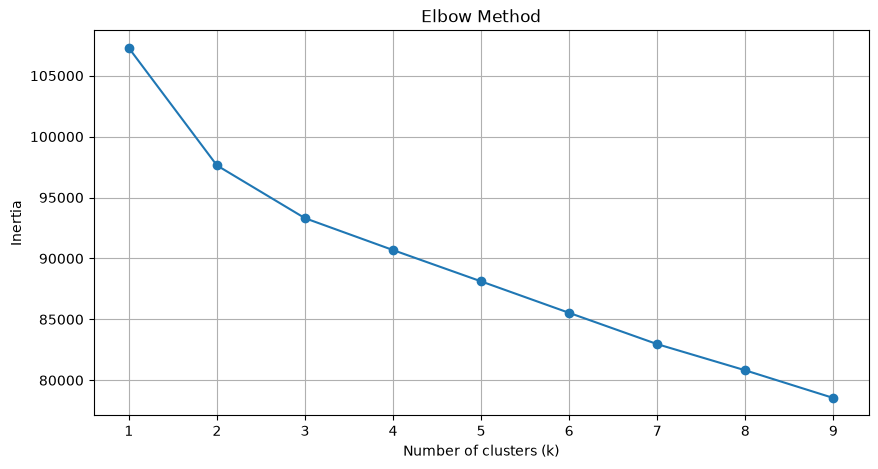

In [38]:
inertias = []
k_values = range(1, 10)

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertias.append(kmeans.inertia_)

plt.figure(figsize=(10, 5))
plt.plot(k_values, inertias, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()


In [39]:
optimal_k = 3

kmeans_model = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
cluster_labels = kmeans_model.fit_predict(X_scaled)

# Add cluster labels to a copy of the processed data.
clustered_data = df.copy()
clustered_data["Cluster"] = cluster_labels

display(clustered_data.head())


,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,QTR_ID,MONTH_ID,YEAR_ID,MSRP,PRODUCTCODE,PRODUCTLINE_Classic Cars,...,COUNTRY_Japan,COUNTRY_Norway,COUNTRY_Philippines,COUNTRY_Singapore,COUNTRY_Spain,COUNTRY_Sweden,COUNTRY_Switzerland,COUNTRY_UK,COUNTRY_USA,Cluster
0,30,95.70,2,2871.00,1,2,2003,95,0,0,...,0,0,0,0,0,0,0,0,1,1
1,34,81.35,5,2765.90,2,5,2003,95,0,0,...,0,0,0,0,0,0,0,0,0,1
2,41,94.74,2,3884.34,3,7,2003,95,0,0,...,0,0,0,0,0,0,0,0,0,0
3,45,83.26,6,3746.70,3,8,2003,95,0,0,...,0,0,0,0,0,0,0,0,1,0
4,49,100.00,14,5205.27,4,10,2003,95,0,0,...,0,0,0,0,0,0,0,0,1,0


In [40]:
cluster_counts = clustered_data["Cluster"].value_counts().sort_index()
display(cluster_counts.rename_axis("Cluster").to_frame("Number of records"))


,Number of records
Cluster,
0,1384
1,1282
2,157


In [41]:
pca = PCA(n_components=2, random_state=42)
reduced_data = pca.fit_transform(X_scaled)

reduced_df = pd.DataFrame(reduced_data, columns=["PCA1", "PCA2"])
reduced_df["Cluster"] = cluster_labels

# Transform the K-Means centers into the same two-dimensional PCA space.
reduced_centers = pca.transform(kmeans_model.cluster_centers_)


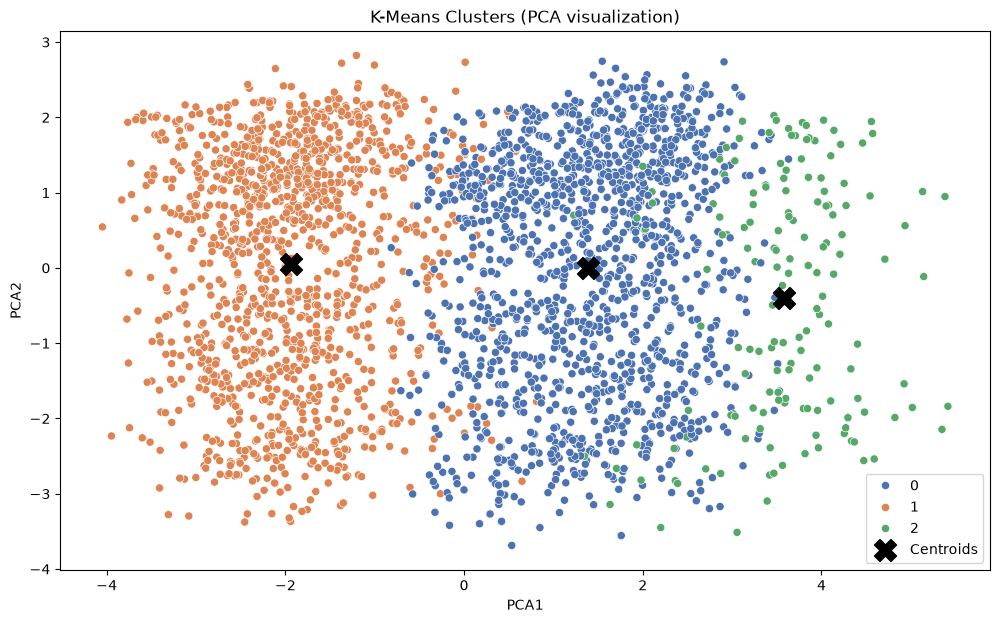

In [42]:
plt.figure(figsize=(12, 7))
sns.scatterplot(
    data=reduced_df,
    x="PCA1",
    y="PCA2",
    hue="Cluster",
    palette="deep",
    s=35
)
plt.scatter(
    reduced_centers[:, 0],
    reduced_centers[:, 1],
    color="black",
    marker="X",
    s=250,
    label="Centroids"
)
plt.title("K-Means Clusters (PCA visualization)")
plt.legend()
plt.show()


In [43]:
clustered_data.to_csv("sales_data_with_clusters.csv", index=False)
print("Saved: sales_data_with_clusters.csv")


Saved: sales_data_with_clusters.csv
